#WELCOME TO INTRO TO SQL
Today we will learn how to use SQL to manage, retrieve and manipulate data in relational databases.



##Why is SQL very popular?


*   Free to use and open source
*   Ideal for both small and large applications
*   Very fast, reliable, scalable, and easy to use
*   Cross platfrom (means we can use it alongside other programming languages like python and R to manipulate and qeuery data but we'll explore that later)





FUN FACT: The 'My' in MySQL is named after co-founder Ulf Michael "Monty" Widenius's daughter: My  (:o

#Understanding the Database

Before performing queries or writting any kind of query it is always important to understand the database that you pulling the data from and understanding the data you are working with.

##What is a Relational Database? Are they different from regular Databases?
Relational Databases are a **specific type** of database that stores data in tables with rows and columns, linking the tables together using unique keys (Primary and Foreign key) to prevent data duplication.

**Primary Key** is a columns that contains unique values, for example suspect_id which helps you from getting confused with two or more suspects with the same name.

**Foreign Key** is a column that references a primary key in another table, helping establish a relationship between tables.

More on [Primary and Foreign Key](https://www.geeksforgeeks.org/dbms/difference-between-primary-key-and-foreign-key/).

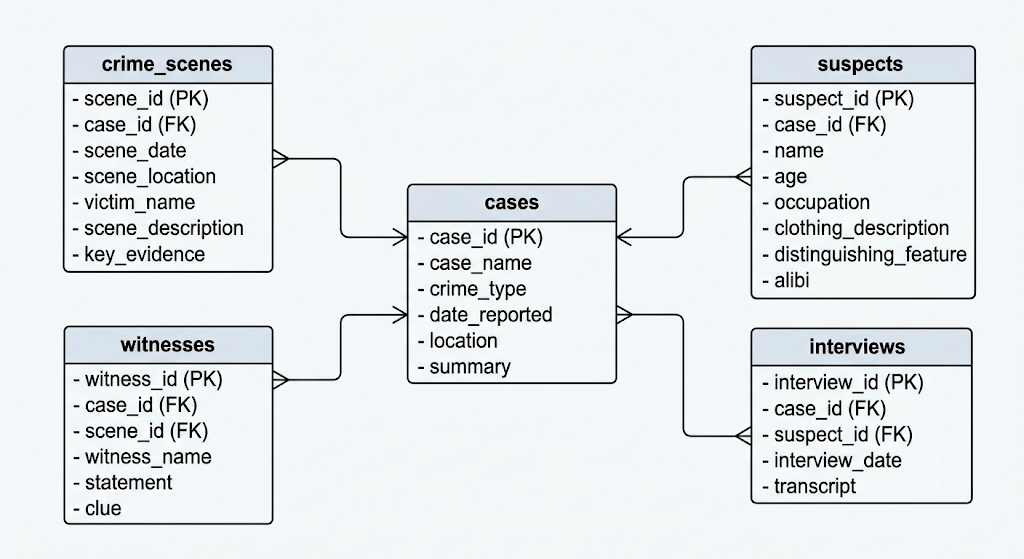

##Another few terms that might come in handy:


*   Attribute: it refers to specific column or property of a table.
*   Record: A single, complete entry or row in a table.
*   Table: A grid of rows and columns where data is stored.
*   Schema: The visual layout or structure that defines how a table is organized including its records and relationships.




##A few SQL commands that can be used to describe the database/tables

**.SCHEMA** is used to gives you the structure of the tables, this includes table, column names, relationship between tables, columns datatypes, etc.
By specifying **.SCHEMA Table_Name**, you will get the information for the specified table.

**.TABLES** used to retrieve the table names in the database.

**PRAGMA table_info('table_name')** the table specified table but also gives you information about the number of null values and if there are any default values in the table

### Example of using .schema

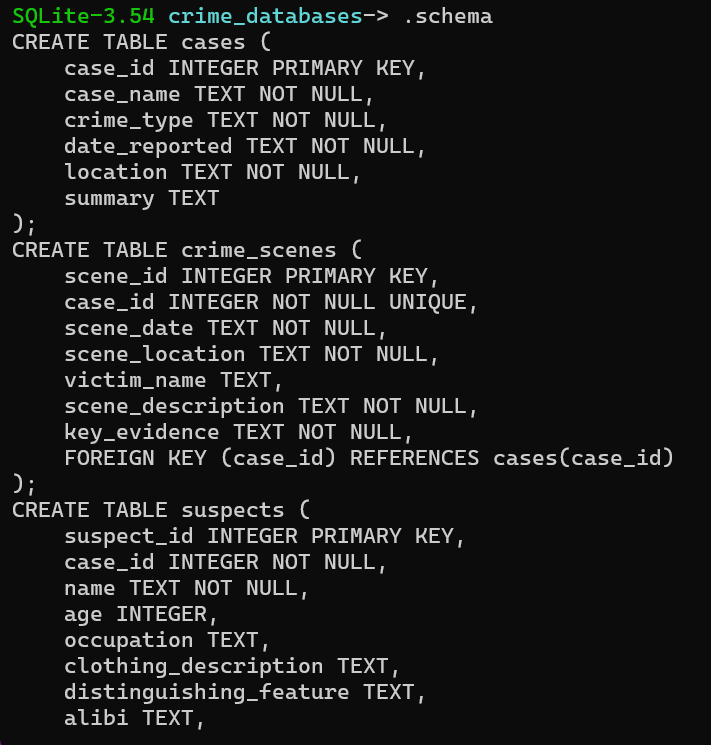

*P.S. **.SCHEMA** shows the schemastics of all the tables but i could'nt fit the entire image*

###Example of using .tables

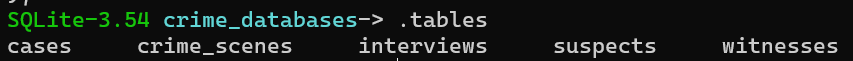

###Example of using PRAGMA table_info('table_name')

In [ ]:
PRAGMA table_info('interviews');

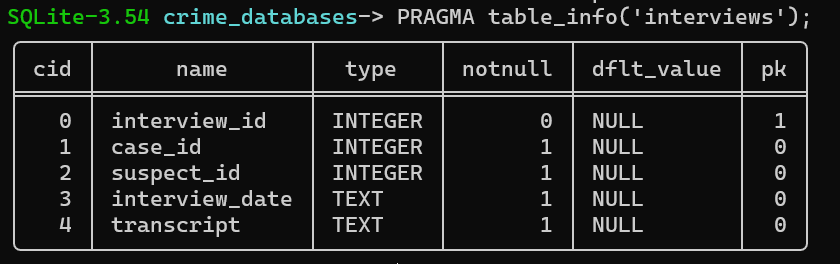

#SQL QUERIES

The **SELECT** statement in SQL is used to retrieve data from the table along with the **FROM** which is a keyword used to specify the table you want to select the data from.

Now to perfrom this tasks you should use copypaste the required queries and database to [sqlonline](https://sqliteonline.com/) since python ain't build for SQL.

In [ ]:
'''The general structure of the queries will look something like this
This query will simply return all the data from the specified columns
and specified table'''
SELECT COLUMN_NAMES,..... FROM TABLE_NAME ;

In [ ]:
'''Here is a simple query using SELECT AND FROM keywords
The query below retrieves the data from the 'name' and 'age' columns
from the suspects tables'''
SELECT NAME,AGE FROM SUSPECTS ;

NOTE: The **Semicolon(;)** is essential part of every query and must be put at the end of the query otherwise SQL won't know where the query ends and it will not be execute your query.

Also, if you want the display all the columns from the table at the same type,
instead of typing all the column names you colud simply just use an asterisk(*)

In [ ]:
#SYNTAX
SELECT * FROM TABLE_NAME ;

The **WHERE** clause in SQL is used to filter data that satisfies a spcific conditon.

SQl requires **text values** to be in single quotation marks however **numeric values** do not need to be enclosed in quotes.

for more information on the uses of the [**WHERE**](https://www.w3schools.com/sql/sql_where.asp) clause.

In [ ]:
#SYNTAX
SELECT COLUMN_NAMES,...... FROM TABLE_NAME WHERE CONDITION;

In [ ]:
'''Here is a query using the 'WHERE' clause
This query will only retrieve the data where the suspects are older than 35'''
SELECT NAME, AGE FROM SUSPECTS WHERE AGE >= 35 ;

Some other common  **clauses/keywords** used in SQL:


*   DISTINCT: It is used retrieve all the unique values in a column.
*   ORDER BY: Sorts the data in ascending or descending order.
*   LIMIT: Restricts the number of records retrieved.
*   LIKE: Searches for text.




NOTE: Also SQL is not case sensitive even when mentioning record values, column names or even table names hence why you will see queries with either upper or lower caes or maybe even both.

Want to take a wild guess at what this query does? (dw if you get it wrong we are all here to learn :) )

In [ ]:
#explain better(SELF NOTE)
select case_name, crime_type, date_reported from cases
where date_reported BETWEEN '1980-%' and '1985-%'
AND crime_type like 'theft'
ORDER BY DATE_REPORTED DESC;

####Answer


Here this query retrieves the data from cases that are listed as thefts tand have taken  place from 1980 - 1985

As you can see I have used a '%' symbol in the query, this '%' is a **wildcard character** which basically acts as zero, one or multiple characters in string searches where you do not know the ending or starting characters.

Its especially usefull in cases where you maybe searching for data within specific dates or to find cases with a specific word like '%Robbery%'.

For more information on [Wildcard Charcters](https://www.w3schools.com/sql/sql_wildcards.asp).



#AGGERGATE functions

What is a aggregate function?

An **aggregate function** is a function that performs a calculation on a set of values, and returns a single value.

The most commonly used SQL aggregate functions are:

*   MIN() - returns the smallest value of a column
*   MAX() - returns the largest value of a column
*   COUNT() - returns the number of rows in a set
*   SUM() - returns the sum of a numerical column
*   AVG() - returns the average value of a numerical column


In [ ]:
#This query retrieves the number of theft caese from the cases table
SELECT COUNT(*) AS THEFT_CASES FROM CASES
WHERE CRIME_TYPE LIKE 'THEFT';

Also in the the above query we can see the use of the **'AS'** keyword. This is bascially used to make a column name more readable.

for example in the above query instead of displaying the column name as 'COUNT(*)' it will display 'THEFT_CASES' and this change will only last for the duration of that query.

NOTE: COUNT(*) counts all the values in a columns including **NULL** values whereas COUNT(column_name) counts all **NON_NULL** values completely ignoring null values.

Also this does not apply to other aggregrate functions.

#Case #001: The Vanishing Briefcase

Set in the gritty 1980s, a valuable briefcase has disappeared from the Blue Note Lounge. A witness reported that a man in a trench coat was seen fleeing the scene. Investigate the crime scene, review the list of suspects, and examine interview transcripts to reveal the culprit.

###Objectives


1.  Retrieve the correct crime scene details to gather the key clue.
2.  Identify the suspect whose profile matches the witness description.
3.  Verify the suspect using their interview transcript.

Click **'>'** to reveal the answers to the tasks

#####**Task 1** - Retrieve the crime scene details fro Case 1

In [ ]:
SELECT * FROM CRIME_SCENES
WHERE SCENE_LOCATION LIKE '%Blue Note Lounge%';

#####**Task 2** - Retrieve the witness statements and clues from Task 1

In [ ]:
SELECT witness_name, statement, clue
FROM witnesses
WHERE case_id = 1;

#####**Task 3**- Find the suspects matching the witness's colthing clue

In [ ]:
SELECT suspect_id, name, age, distinguishing_feature
FROM suspects
WHERE case_id = 1
AND clothing_description LIKE '%trench coat%';

#####**Task 4** - Retrieve thta suspect's interview transcript

In [ ]:
SELECT *
FROM interviews
WHERE suspect_id = 201;

#GROUP BY and HAVING

The **GROUP BY** statement is used to group together similar data, for example you may want to know the number suspects in each age group or maybe the sum of all the different crime types.

The **GROUP BY** is almost always accompanied by an aggregrate functions to perform calculations on each group.

NOTE: When using the **GROUP BY**, you must always display the column which you want to group the data by, otherwise it will show an error.

In [ ]:
#SYNTAX
SELECT COLUMN_NAMES,.... FROM TABLE_NAME
GROUP BY COLUMN_1;

The **HAVING** clause is used to impose certain conditions after the grouping of data is done by the GROUP BY.

And unlike the WHERE clause which filter rows of data the **HAVING** clause filters the groups after an aggregration has been performed.

In [ ]:
#SYNTAX
SELECT COLUMN_NAMES,....., AGGREGRATE_FUNCTION(COLUMN_NAME) FROM TABLE_NAME
GROUP BY COLUMN_1
HAVING CONDITION;

A little something extra:

What to do if you want to perform a query which only retiresves data that does not match the condition?

Its pretty simple actually, you only have to add the **'NOT'** operator in your WHERE claus or you could always use the trusty **'!='** not equals sign.

In [ ]:
'''Here this query will display records of all the suspects that are not aged
between 24 and 35'''
SELECT NAME, AGE FROM SUSPECTS WHERE NOT AGE BETWEEN 24 AND 35 ;

#CASE #002

##Case briefing
In the neon glow of 1980s Los Angeles, the West Hollywood Records store was rocked by a daring theft. A prized vinyl record, worth over $10,000, vanished during a busy evening, leaving the store owner desperate for answers. Vaguely recalling the details, you know the incident occurred on July 15, 1983, at this famous store. Your task is to track down the thief and bring them to justice.


Objectives
1. Retrieve the crime scene report for the record theft using the known date and location.
2. Retrieve witness records linked to that crime scene to obtain their clues.
3. Use the clues from the witnesses to find the suspect in the suspects table.
4. Retrieve the suspect's interview transcript to confirm the confession

Click **'>'** to reveal the answers to the task

#####**Task 1** - FInd the case ID using its date and location

In [ ]:

SELECT case_id, case_name, date_reported, location
FROM cases
WHERE date_reported = '1983-07-15'
AND LOCATION LIKE '%West Hollywood Records%' ;

#####**Task 2**- Retrieve the crime scene the case ID from Task 1

In [ ]:
SELECT * FROM crime_scenes
WHERE case_id = 2;

#####**Task 3** - Retrieve the witness using the scene ID from Task 2

In [ ]:
SELECT witness_name, statement, clue
FROM witnesses
WHERE scene_id = 102;

#####**Task 4** – Identify the suspect mentioned by multiple witnesses.

In [ ]:
SELECT suspect_id, COUNT(DISTINCT witness_name) AS WITNESS_COUNT
FROM witnesses
WHERE case_id = 2
GROUP BY suspect_id
HAVING COUNT(DISTINCT witness_name) > 1;

#####**Task 5** - Filter the suspects using both witness clues.

In [ ]:
SELECT name, age, occupation, distinguishing_feature
FROM suspects
WHERE suspect_id = 203;

#####**Task 6** - Retrieve the interview for the suspect found in Task 4

In [ ]:
SELECT transcript
FROM interviews
WHERE suspect_id = 203;

SyntaxError: invalid syntax (2194441607.py, line 2)

#JOIN Statements

SQL **JOIN** staement are used ot retireve data from 2 or more tables based on a common related column.
This techniques helps in creating meaningful results by retrieving information/records from multiple table and thus improving the data analysis.

##Types of SQL JOINS
SQL joins are categorized into different types based on how rows from two tables are matched and combined, and they are mainly classified into three distinct types:


*   INNER JOIN
*   LEFT JOIN
*   RIHT JOIN



###1.INNER JOIN
**INNER JOIN** is used to retrieve rows where matching values exist in both tables.

If we use a venn diagram to understand what data it retrieves, it would look something like this:


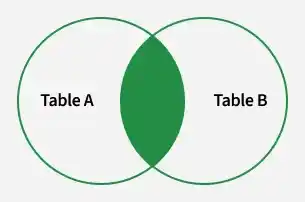

In [ ]:
#SYNTAX
SELECT A.column_name1, A.column_name2, B.column_name2,...
FROM tableA AS A
INNER JOIN tableB AS B
ON A.matching_column = B.matching_column;

NOTE: The 'table_name as Tb' is called as an alias where we shorten the name of the table instead of writting it again and again

###2.LEFT JOIN
In SQL, the **LEFT JOIN** (also called LEFT OUTER JOIN) retrieves all records from the left table and only the matching records from the right table. If no match is found, NULL values are returned for the right table columns.

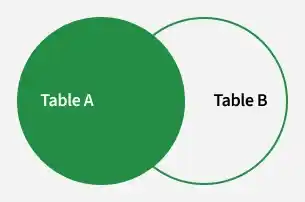

In [ ]:
#SYNTAX
SELECT A.*, B.column1, ... #table_name.* is simpler way instead of writting all the column names
FROM tableA AS A
LEFT JOIN tableB AS B
ON A.matching_column = B.matching_column;

###3.RIGHT JOIN
In SQL, the **RIGHT JOIN** (also called RIGHT OUTER JOIN) is used to combine rows from two tables based on a related column. It returns all records from the right table and only the matching records from the left table. If there is no match in the left table, the result will show NULL values for the left table’s columns

In [ ]:
#SYNTAX
SELECT A.column1, A.column2, B.*, ...
FROM tableA AS A
RIGHT JOIN tableB AS B
ON A.matching_column = B.matching_column

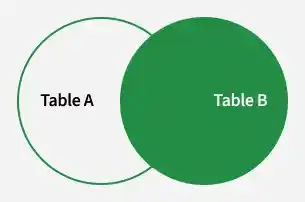

In [ ]:
#Examples
SELECT c.case_id, c.case_name, s.suspect_id, s.name, s.age
FROM cases as c
INNER JOIN suspects as s
ON c.case_id = s.case_id;

In [ ]:
#Examples
SELECT c.case_id, c.case_name, s.suspect_id, s.name
FROM cases as c
LEFT JOIN suspects as s
ON c.case_id = s.case_id;

#Subqueries

What is a Subquery?

A subquery allows SQL queries to be more modular by handling tasks that would otherwise require multiple separate queries.

Subqueries are mainly used to:

*   Filtering records based on data from related tables.
*   Aggregating data and performing calculations dynamically.
*   Cross-referencing data between tables to retrieve specific insights.
*   Conditionally selecting rows without requiring explicit joins or external code logic.


In [ ]:
#GENERAL SYNTAX

##Types of Subqueries

* Single-Row Subquery
* Multi-Row Subquery
* Correlated Subquery



###Single-Row Subquery

A single-row subquery is a subquery where the inner query returns only one value.

* Returns exactly one row as the result.
* Commonly used with comparison operators such as =, >, <


In [ ]:
#Examples
SELECT suspect_id, name, age
FROM suspects
WHERE age > (
    SELECT AVG(age)
    FROM suspects
);

Why is it a single-row subquery?

Because the inner query returns only one value that is the average age.

###Multi-Row Subquery
A multi-row subquery is a subquery where the inner query returns more than one value.

* Returns multiple rows as the result.
* Requires operators that can handle multiple values such as IN, NOT IN, [ANY or ALL](https://www.geeksforgeeks.org/sql/sql-all-and-any/)

In [ ]:
#Examples
SELECT case_id, case_name, crime_type
FROM cases
WHERE case_id IN (
    SELECT case_id
    FROM suspects
);

Here the inner query retrieves all the case_id and the outer query then retrieves only thos cases where the case_id match

###Correlated Subquery
A correlated subquery is a subquery that depends on the outer query for its values.

* A dependent subquery: it references columns from the outer query.
* Executed once for each row of the outer query, making it slower for large datasets.

In [ ]:
#Examples
SELECT c.case_id, c.case_name
FROM cases as c
WHERE (
    SELECT COUNT(*)
    FROM suspects as s
    WHERE s.case_id = c.case_id
) > 1;

How it works?

1. The outer query selects records from CASES.
2. The inner query counts the number of suspects associated with each case.
3. suspects.case_id = cases.case_id links the inner query to the outer query.
4. As a result only cases with more than one suspect are returned.



What is the difference between non_correlated queries and correlated queries?

Well for unlike the previous examples, the inner query is dependent on each row that is being considered by the outer query.

If you want to take a deeper dive into using subqueries: [A comprehensive guide to SQL Subqueries](https://www.datacamp.com/tutorial/sql-subquery).

#CASE #003

##The Miami Marina Murder
A body was found floating near the docks of Coral Bay Marina in the early hours of August 14, 1986. Your job, detective, is to find the murderer and bring them to justice. This case might require the use of JOINs, wildcard searches, and logical deduction. Get to work, detective.

Objectives
1. Find the murderer. ( Start by finding the crime scene and go from there )

Click **'>'** to reveal the answers to solve the task

#####**Task 1** - Locate the case and crime scene using the date and location

In [ ]:
SELECT cases.case_name, cases.date_reported,
       crime_scenes.scene_location,
       crime_scenes.victim_name,
       crime_scenes.key_evidence
FROM cases
INNER JOIN crime_scenes
ON cases.case_id = crime_scenes.case_id
WHERE cases.date_reported = '1986-08-14';

#####**Task 2** - Use a suitable JOIN to pull the crime scene and witness records

In [ ]:
SELECT crime_scenes.key_evidence,
       witnesses.witness_name,
       witnesses.statement,
       witnesses.clue
FROM crime_scenes
INNER JOIN witnesses
ON crime_scenes.scene_id = witnesses.scene_id
WHERE crime_scenes.case_id = 3;

#####**Task 3** - Use a subquery to match the suspect to clues in the witness reports

In [ ]:
SELECT name, age, occupation, distinguishing_feature
FROM suspects
WHERE case_id = 3
AND suspect_id IN (
    SELECT suspect_id
    FROM witnesses
    WHERE case_id = 3
    AND clue LIKE '%blue raincoat%'
);

#####**Task 4** - Use a Subquery to check for suspects with Dock 4 access

In [ ]:
SELECT name, distinguishing_feature
FROM suspects
WHERE case_id = 3
AND suspect_id IN (
    SELECT suspect_id
    FROM witnesses
    WHERE case_id = 3
    AND clue LIKE '%Dock 4 key%'
);

#####**Task 5** - Join the suspect and interview records to retrieve the trancsript to find the culprit


In [ ]:
SELECT suspects.name,
       interviews.transcript
FROM suspects
INNER JOIN interviews
ON suspects.suspect_id = interviews.suspect_id
WHERE suspects.case_id = 3
AND suspects.name = 'Elena Voss';

#Integrating your SQL QUERIES with PYHTON